# 08 · Partial Fine-tuning (GreenPath)

**Objective:** On the same ten-target dataset produced by Notebook 05, train **M2a ResNet50 (unfreeze `layer4` and the regression head)** and **M2b DINOv2-S (unfreeze the last two Transformer blocks, final normalization, and regression head)**. Compare against Notebook 07's B0, B1, frozen ResNet50, frozen DINOv2, frozen CLIP, and M3 baselines.

- **Inputs:** `data/datasets/v1/{train,val,test}.parquet`, `schema.json`, and `processed/tiles/`. No changes to the files produced by Notebooks 01–07.
- **Outputs:** Model checkpoints, training history, validation/test metrics, per-dimension results, and comparison tables under `data/results/finetuning-.../`.
- **Evaluation protocol:** Tune and select checkpoints using training/validation data only; evaluate on the held-out test set once at the end. With roughly 160 usable cells, this is an exploratory comparison and fine-tuning may overfit.
- Notebook 07's frozen embeddings use `timm` pretrained weights; this notebook uses the corresponding `timm` pretrained encoders and ImageNet normalization.
- **Runtime:** Google Colab → Runtime → Change runtime type → T4 GPU.


## 0. Mount Google Drive and set the working directory

In [1]:
from google.colab import drive, userdata
from pathlib import Path
import os

drive.mount('/content/drive')
PROJECT_ROOT = Path('/content/drive/MyDrive/Oct17DimensionTrainingVLM')
assert PROJECT_ROOT.exists(), f'Project not found: {PROJECT_ROOT}'
os.chdir(PROJECT_ROOT)
# This notebook does not call Gemini or Mapillary APIs, so API keys are not needed.
print('Working directory:', os.getcwd())
print('Data folder exists:', (PROJECT_ROOT / 'data').exists())

Mounted at /content/drive
Working directory: /content/drive/MyDrive/Oct17DimensionTrainingVLM
Data folder exists: True


## 1. Install dependencies and configure the experiment
Keep `DATASET_VERSION = "v1"`; do not rename or modify the data produced by the first seven notebooks. Start with `DRY_RUN = True` to smoke-test the pipeline, then switch to `False` and rerun training for the full experiment.

In [ ]:
import sys, subprocess
subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'timm', 'pandas', 'pyarrow', 'scipy', 'matplotlib', 'tqdm', 'pillow'], check=True)

DATASET_VERSION = 'v1'
STORAGE = 'drive'
GCS_ROOT = 'gs://greenpath-data'
DRIVE_ROOT = '/content/drive/MyDrive/Oct17DimensionTrainingVLM/data'
LOCAL_ROOT = './data'

DRY_RUN = False             # True: 2 epochs smoke test; False: full experiment
SEED = 42
BATCH_SIZE = 8
NUM_WORKERS = 0             # Drive-backed image reading: safer with 0
EPOCHS = 2 if DRY_RUN else 25
PATIENCE = 3 if DRY_RUN else 6
HEAD_LR = 3e-4
BACKBONE_LR = 1e-5
WEIGHT_DECAY = 1e-4
USE_AMP = True
BACKBONES = ['resnet50', 'dinov2_s']  # CLIP remains in 06/07 frozen comparison
assert STORAGE == 'drive'
DATA_ROOT = Path(DRIVE_ROOT)
assert DATA_ROOT.is_dir()
print('Data root:', DATA_ROOT)

Data root: /content/drive/MyDrive/Oct17DimensionTrainingVLM/data


## 2. Load the fixed dataset, ten targets, and splits
Reuse the `train`, `val`, and `test` splits saved by Notebook 05; do not reshuffle or resplit. Targets are in [0, 1]. Missing labels are excluded from the loss and metrics.

In [ ]:
import json, random, datetime, time, gc
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm.auto import tqdm
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import timm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| CUDA:', torch.cuda.is_available())
if DEVICE.type != 'cuda':
    print('WARNING: GPU is strongly recommended. Set Colab runtime to T4 GPU.')

DS_DIR = DATA_ROOT / 'datasets' / DATASET_VERSION
schema = json.loads((DS_DIR / 'schema.json').read_text(encoding='utf-8'))
DIMS = schema['targets']
assert len(DIMS) == 10, f'Expected ten targets, got {DIMS}'
train_df = pd.read_parquet(DS_DIR / 'train.parquet')
val_df = pd.read_parquet(DS_DIR / 'val.parquet')
test_df = pd.read_parquet(DS_DIR / 'test.parquet')
assert all('tile_path' in df and set(DIMS).issubset(df.columns) for df in (train_df, val_df, test_df))
assert not (set(train_df.cell_id) & set(val_df.cell_id) or set(train_df.cell_id) & set(test_df.cell_id) or set(val_df.cell_id) & set(test_df.cell_id))
print('Dataset:', DATASET_VERSION, '| Train:', len(train_df), '| Val:', len(val_df), '| Test:', len(test_df))
print('Dimensions:', DIMS)
print('Labeled values per split:')
for name, df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(name, df[DIMS].notna().sum().to_dict())
assert len(train_df) and len(val_df) and len(test_df), 'A data split is empty.'

RUN_ID = 'finetuning-' + datetime.datetime.now(datetime.timezone.utc).strftime('%Y%m%dT%H%M%SZ') + ('-dryrun' if DRY_RUN else '')
OUT_DIR = DATA_ROOT / 'results' / RUN_ID
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Run output:', OUT_DIR)

Device: cuda | CUDA: True
Dataset: v1 | Train: 67 | Val: 39 | Test: 54
Dimensions: ['tree_canopy', 'greenery', 'water_visibility', 'open_landscape', 'urban_density', 'historic_character', 'commercial_activity', 'bike_infrastructure', 'road_environment', 'scenic_appeal']
Labeled values per split:
train {'tree_canopy': 67, 'greenery': 67, 'water_visibility': 67, 'open_landscape': 67, 'urban_density': 67, 'historic_character': 67, 'commercial_activity': 67, 'bike_infrastructure': 67, 'road_environment': 67, 'scenic_appeal': 67}
val {'tree_canopy': 39, 'greenery': 39, 'water_visibility': 39, 'open_landscape': 39, 'urban_density': 39, 'historic_character': 39, 'commercial_activity': 39, 'bike_infrastructure': 39, 'road_environment': 39, 'scenic_appeal': 39}
test {'tree_canopy': 54, 'greenery': 54, 'water_visibility': 54, 'open_landscape': 54, 'urban_density': 54, 'historic_character': 54, 'commercial_activity': 54, 'bike_infrastructure': 54, 'road_environment': 54, 'scenic_appeal': 54}
Run 

## 3. Image preprocessing and DataLoaders
Match Notebook 06: center-crop the input to 224×224 and apply ImageNet mean/std normalization. Training augmentation uses random horizontal/vertical flips and right-angle rotations, appropriate for overhead imagery. Validation and test transforms are deterministic.

In [ ]:
from torchvision import transforms

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class TileDataset(Dataset):
    def __init__(self, frame, transform):
        self.df = frame.reset_index(drop=True)
        self.transform = transform
        self.y = self.df[DIMS].to_numpy(dtype=np.float32)
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        r = self.df.iloc[idx]
        p = DATA_ROOT / str(r.tile_path)
        with Image.open(p) as im:
            x = self.transform(im.convert('RGB'))
        y = torch.from_numpy(self.y[idx].copy())
        return x, y

def loader(frame, training):
    return DataLoader(TileDataset(frame, train_tf if training else eval_tf),
                      batch_size=BATCH_SIZE, shuffle=training, num_workers=NUM_WORKERS,
                      pin_memory=(DEVICE.type == 'cuda'))

train_loader = loader(train_df, True)
val_loader = loader(val_df, False)
test_loader = loader(test_df, False)
x, y = next(iter(train_loader))
print('One batch:', tuple(x.shape), tuple(y.shape), '| NaN labels:', int(torch.isnan(y).sum()))

One batch: (8, 3, 224, 224) (8, 10) | NaN labels: 0


## 4. Models: M2a and M2b
Freeze all pretrained encoder parameters first, then unfreeze only the specified final layers. A new ten-output regression head followed by sigmoid restricts predictions to [0, 1]. The trainable encoder parameters and new head use separate learning rates.

In [ ]:
SOURCES = {
    'resnet50': 'resnet50.a1_in1k',
    'dinov2_s': 'vit_small_patch14_dinov2.lvd142m',
}

def make_model(name):
    encoder = timm.create_model(SOURCES[name], pretrained=True, num_classes=0,
                                **({'img_size': 224} if name == 'dinov2_s' else {}))
    for p in encoder.parameters(): p.requires_grad = False
    if name == 'resnet50':
        for p in encoder.layer4.parameters(): p.requires_grad = True
    elif name == 'dinov2_s':
        for block in encoder.blocks[-2:]:
            for p in block.parameters(): p.requires_grad = True
        # Final norm is also trainable.
        for p in encoder.norm.parameters(): p.requires_grad = True
    else:
        raise ValueError(name)
    head = nn.Linear(encoder.num_features, len(DIMS))
    class Regressor(nn.Module):
        def __init__(self, enc, regression_head):
            super().__init__(); self.encoder = enc; self.head = regression_head
        def forward(self, x): return torch.sigmoid(self.head(self.encoder(x)))
    model = Regressor(encoder, head).to(DEVICE)
    backbone_params = [p for p in model.encoder.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW([
        {'params': backbone_params, 'lr': BACKBONE_LR},
        {'params': model.head.parameters(), 'lr': HEAD_LR},
    ], weight_decay=WEIGHT_DECAY)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'{name}: {trainable:,}/{total:,} trainable parameters ({100*trainable/total:.1f}%)')
    return model, optimizer

def masked_loss(pred, target):
    valid = torch.isfinite(target)
    if not valid.any(): return pred.sum() * 0
    # Huber is less sensitive to outlier pseudo-labels than MSE.
    return nn.functional.smooth_l1_loss(pred[valid], target[valid], beta=0.1)

for name in BACKBONES:
    model, optim = make_model(name)
    del model, optim
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

resnet50: 14,985,226/23,528,522 trainable parameters (63.7%)
dinov2_s: 3,555,082/21,632,650 trainable parameters (16.4%)


## 5. Training, validation, and early stopping
Select the best checkpoint by mean validation MAE; do not use test data for model selection. Use AdamW, a low encoder learning rate, masked Huber loss, early stopping, and gradient clipping to reduce overfitting risk.

In [ ]:
def predict_loader(model, dl):
    model.eval(); ps, ys = [], []
    with torch.no_grad():
        for xb, yb in dl:
            xb = xb.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type='cuda', enabled=(USE_AMP and DEVICE.type == 'cuda')):
                pred = model(xb)
            ps.append(pred.float().cpu().numpy()); ys.append(yb.numpy())
    return np.concatenate(ys), np.concatenate(ps)

def metrics_by_dim(y, pred):
    rows = []
    for j, d in enumerate(DIMS):
        ok = np.isfinite(y[:, j]) & np.isfinite(pred[:, j])
        a, b = y[ok, j], pred[ok, j]
        if len(a):
            mae = float(np.mean(np.abs(a - b)))
            rmse = float(np.sqrt(np.mean((a-b)**2)))
        else: mae = rmse = np.nan
        rho = float(spearmanr(a, b).correlation) if len(a) >= 5 and np.ptp(a) > 0 and np.ptp(b) > 0 else np.nan
        rows.append({'dimension': d, 'n': int(ok.sum()), 'MAE': mae, 'RMSE': rmse, 'Spearman': rho})
    return pd.DataFrame(rows)

def train_one(name):
    model, optimizer = make_model(name)
    scaler = torch.amp.GradScaler('cuda', enabled=(USE_AMP and DEVICE.type == 'cuda'))
    best_mae, bad_epochs, history = float('inf'), 0, []
    ckpt = OUT_DIR / f'{name}_partial_best.pt'
    for epoch in range(1, EPOCHS + 1):
        model.train(); loss_sum, steps = 0.0, 0
        for xb, yb in tqdm(train_loader, desc=f'{name} epoch {epoch}/{EPOCHS}', leave=False):
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', enabled=(USE_AMP and DEVICE.type == 'cuda')):
                pred = model(xb); loss = masked_loss(pred, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_((p for p in model.parameters() if p.requires_grad), 1.0)
            scaler.step(optimizer); scaler.update()
            loss_sum += float(loss.detach()); steps += 1
        vy, vp = predict_loader(model, val_loader)
        vm = metrics_by_dim(vy, vp)
        val_mae = float(vm.MAE.mean())
        history.append({'model': name, 'epoch': epoch, 'train_loss': loss_sum/max(steps, 1),
                        'val_MAE': val_mae, 'val_RMSE': float(vm.RMSE.mean()),
                        'val_Spearman': float(vm.Spearman.mean())})
        print(f'{name} epoch {epoch}: train loss {loss_sum/max(steps,1):.4f}, val MAE {val_mae:.4f}, Spearman {vm.Spearman.mean():.3f}')
        if np.isfinite(val_mae) and val_mae < best_mae - 1e-5:
            best_mae, bad_epochs = val_mae, 0
            torch.save({'state_dict': model.state_dict(), 'model_name': name,
                        'epoch': epoch, 'dims': DIMS, 'dataset_version': DATASET_VERSION}, ckpt)
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print('Early stopping.'); break
    if not ckpt.exists(): raise RuntimeError(f'No checkpoint for {name}')
    saved = torch.load(ckpt, map_location=DEVICE, weights_only=True)
    model.load_state_dict(saved['state_dict'])
    vy, vp = predict_loader(model, val_loader)
    val_detail = metrics_by_dim(vy, vp).assign(model=name, split='val')
    return model, pd.DataFrame(history), val_detail, vp

trained_models = {}
logs, val_details = [], []
for name in BACKBONES:
    print('\nTraining:', name)
    model, hist, detail, vp = train_one(name)
    trained_models[name] = model
    logs.append(hist); val_details.append(detail)
    pd.DataFrame({'cell_id': val_df.cell_id, **{f'{d}_pred': vp[:, j] for j, d in enumerate(DIMS)}}).to_csv(OUT_DIR / f'{name}_val_predictions.csv', index=False)
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
history_df = pd.concat(logs, ignore_index=True)
val_detail_df = pd.concat(val_details, ignore_index=True)
history_df.to_csv(OUT_DIR / 'training_history.csv', index=False)
val_detail_df.to_csv(OUT_DIR / 'validation_per_dimension.csv', index=False)
print('Validation results:')
display(val_detail_df.groupby('model')[['MAE', 'RMSE', 'Spearman']].mean().round(3))


Training: resnet50
resnet50: 14,985,226/23,528,522 trainable parameters (63.7%)


resnet50 epoch 1/25:   0%|          | 0/9 [00:00<?, ?it/s]

resnet50 epoch 1: train loss 0.2192, val MAE 0.2752, Spearman 0.019


resnet50 epoch 2/25:   0%|          | 0/9 [00:00<?, ?it/s]

resnet50 epoch 2: train loss 0.1879, val MAE 0.2516, Spearman 0.093


...

dinov2_s epoch 14/25:   0%|          | 0/9 [00:00<?, ?it/s]

dinov2_s epoch 14: train loss 0.0594, val MAE 0.1279, Spearman 0.323


dinov2_s epoch 15/25:   0%|          | 0/9 [00:00<?, ?it/s]

dinov2_s epoch 15: train loss 0.0581, val MAE 0.1219, Spearman 0.319
Early stopping.
Validation results:


,MAE,RMSE,Spearman
model,,,
dinov2_s,0.117,0.151,0.342
resnet50,0.133,0.163,0.337


## 6. Validation learning curves and model selection (no test data)

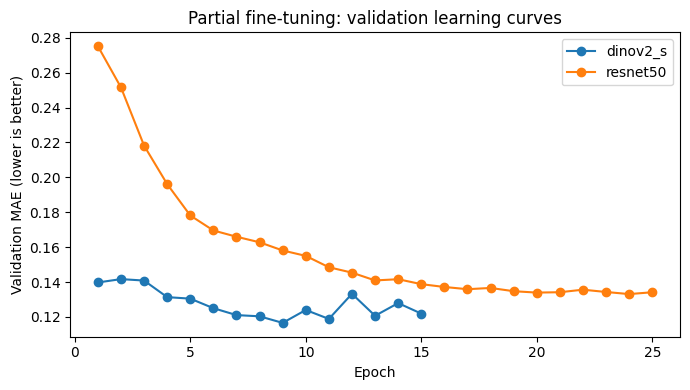

Best fine-tuned model by validation MAE: dinov2_s
Validation MAE: 0.1166


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, group in history_df.groupby('model'):
    ax.plot(group.epoch, group.val_MAE, marker='o', label=name)
ax.set_xlabel('Epoch'); ax.set_ylabel('Validation MAE (lower is better)')
ax.set_title('Partial fine-tuning: validation learning curves'); ax.legend()
plt.tight_layout(); plt.show()

best_val = val_detail_df.groupby('model').MAE.mean().sort_values()
BEST_FT = best_val.index[0]
print('Best fine-tuned model by validation MAE:', BEST_FT)
print('Validation MAE:', round(float(best_val.iloc[0]), 4))

## 7. Final held-out test evaluation (run once)

**Important:** Review the configuration, training curves, and validation metrics before running this section. No hyperparameters are adjusted here. Results may be unstable because the sample size is small.

In [ ]:
# Do not run this cell repeatedly to choose hyperparameters.
test_details, test_preds = [], {}
for name, model in trained_models.items():
    ty, tp = predict_loader(model, test_loader)
    detail = metrics_by_dim(ty, tp).assign(model=name, split='test')
    test_details.append(detail)
    test_preds[name] = tp
    pd.DataFrame({'cell_id': test_df.cell_id, **{f'{d}_pred': tp[:, j] for j, d in enumerate(DIMS)}}).to_csv(
        OUT_DIR / f'{name}_test_predictions.csv', index=False)
ft_test_detail = pd.concat(test_details, ignore_index=True)
ft_test_detail.to_csv(OUT_DIR / 'test_per_dimension_finetuning.csv', index=False)
print('Fine-tuned test results:')
display(ft_test_detail.groupby('model')[['MAE', 'RMSE', 'Spearman']].mean().round(3))

Fine-tuned test results:


,MAE,RMSE,Spearman
model,,,
dinov2_s,0.125,0.161,0.441
resnet50,0.174,0.209,0.215


## 8. Compare with Notebook 07 baselines
Read Notebook 07’s saved `test_model_comparison.csv` without retraining the baseline models. Retain frozen CLIP as a comparator. **Verify that the baseline CSV was produced using the same `datasets/v1` split.**

In [ ]:
import glob
base_files = sorted(DATA_ROOT.glob('results/*/test_model_comparison.csv'), key=lambda p: p.stat().st_mtime, reverse=True)
if not base_files:
    raise FileNotFoundError('Cannot find 07 test_model_comparison.csv; run the additional evaluation cell in Notebook 07 first.')
BASELINE_CSV = base_files[0]
print('Baseline source:', BASELINE_CSV)
base = pd.read_csv(BASELINE_CSV)
required = {'Model', 'MAE', 'RMSE', 'Spearman'}
assert required.issubset(base.columns), f'Missing baseline columns: {required - set(base.columns)}'
ft = ft_test_detail.groupby('model')[['MAE', 'RMSE', 'Spearman']].mean().reset_index()
ft['Model'] = ft.model.map({'resnet50': 'M2a: ResNet50 Partial FT', 'dinov2_s': 'M2b: DINOv2 Partial FT'})
comparison = pd.concat([base[['Model','MAE','RMSE','Spearman']], ft[['Model','MAE','RMSE','Spearman']]], ignore_index=True)
comparison = comparison.sort_values('MAE', ascending=True).reset_index(drop=True)
print('=== Test set comparison (same dataset v1) ===')
display(comparison.round(3))
comparison.to_csv(OUT_DIR / 'test_model_comparison_with_finetuning.csv', index=False)
print('Saved:', OUT_DIR / 'test_model_comparison_with_finetuning.csv')

Baseline source: /content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results/baselines-first-run-20261018T1446/test_model_comparison.csv
=== Test set comparison (same dataset v1) ===


,Model,MAE,RMSE,Spearman
0,M2b: DINOv2 Partial FT,0.125,0.161,0.441
1,Frozen CLIP + Ridge,0.126,0.158,0.519
2,B1: OSM + LightGBM,0.132,0.163,0.553
3,M1: Best Frozen Encoder,0.132,0.164,0.468
4,Frozen DINOv2 + Ridge,0.132,0.164,0.468
5,Frozen ResNet50 + Ridge,0.132,0.170,0.403
6,M3: Image + OSM,0.135,0.170,0.475
7,M2a: ResNet50 Partial FT,0.174,0.209,0.215
8,B0: Mean Baseline,0.174,0.208,0.000


Saved: /content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results/finetuning-20261018T145711Z/test_model_comparison_with_finetuning.csv


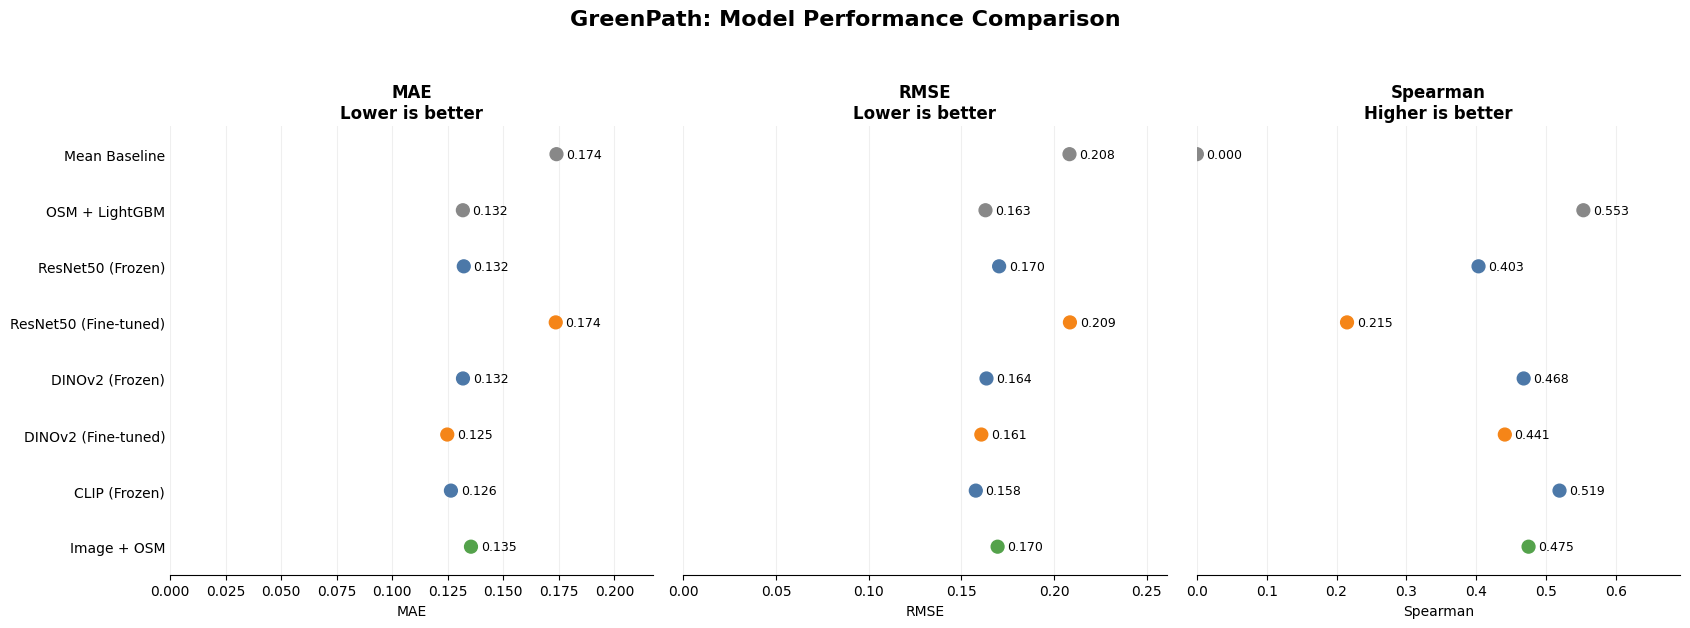

Saved: /content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results/finetuning-20261018T145711Z/model_comparison_dotplot.png


In [4]:
# ============================================================
# GreenPath: Aligned Model Comparison (Dot Plots)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load results
RESULTS_ROOT = Path(
    "/content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results"
)

runs = sorted(
    RESULTS_ROOT.glob("finetuning-*"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

assert runs, "No fine-tuning results found."

result_file = runs[0] / "test_model_comparison_with_finetuning.csv"
df = pd.read_csv(result_file)

# 2. Consistent model order
model_order = [
    "B0: Mean Baseline",
    "B1: OSM + LightGBM",
    "Frozen ResNet50 + Ridge",
    "M2a: ResNet50 Partial FT",
    "Frozen DINOv2 + Ridge",
    "M2b: DINOv2 Partial FT",
    "Frozen CLIP + Ridge",
    "M3: Image + OSM",
]

name_map = {
    "B0: Mean Baseline": "Mean Baseline",
    "B1: OSM + LightGBM": "OSM + LightGBM",
    "Frozen ResNet50 + Ridge": "ResNet50 (Frozen)",
    "M2a: ResNet50 Partial FT": "ResNet50 (Fine-tuned)",
    "Frozen DINOv2 + Ridge": "DINOv2 (Frozen)",
    "M2b: DINOv2 Partial FT": "DINOv2 (Fine-tuned)",
    "Frozen CLIP + Ridge": "CLIP (Frozen)",
    "M3: Image + OSM": "Image + OSM",
}

df = df.set_index("Model").reindex(model_order)

assert df["MAE"].notna().all(), "Some models are missing."

# 3. Colors by model type
colors = [
    "#888888",  # Mean Baseline
    "#888888",  # OSM Baseline
    "#4C78A8",  # Frozen ResNet
    "#F58518",  # Fine-tuned ResNet
    "#4C78A8",  # Frozen DINOv2
    "#F58518",  # Fine-tuned DINOv2
    "#4C78A8",  # Frozen CLIP
    "#54A24B",  # Fusion
]

# 4. Plot
metrics = [
    ("MAE", "Lower is better"),
    ("RMSE", "Lower is better"),
    ("Spearman", "Higher is better"),
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 6),
    sharey=True
)

y = np.arange(len(model_order))

for ax, (metric, direction) in zip(axes, metrics):

    values = df[metric].values

    ax.scatter(
        values,
        y,
        s=85,
        c=colors,
        zorder=3
    )

    # Value labels
    for i, value in enumerate(values):
        ax.annotate(
            f"{value:.3f}",
            (value, i),
            xytext=(7, 0),
            textcoords="offset points",
            va="center",
            fontsize=9
        )

    ax.set_title(
        f"{metric}\n{direction}",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel(metric)

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.tick_params(axis="y", length=0)

    ax.set_ylim(len(y) - 0.5, -0.5)

    # Leave space for numeric labels
    ax.set_xlim(
        0,
        max(values) * 1.25
    )

# 5. Shared model labels
axes[0].set_yticks(y)
axes[0].set_yticklabels(
    [name_map[m] for m in model_order],
    fontsize=10
)

fig.suptitle(
    "GreenPath: Model Performance Comparison",
    fontsize=16,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()

# 6. Save
output_file = runs[0] / "model_comparison_dotplot.png"

plt.savefig(
    output_file,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_file)

Loaded: /content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results/finetuning-20261018T145711Z/test_model_comparison_with_finetuning.csv


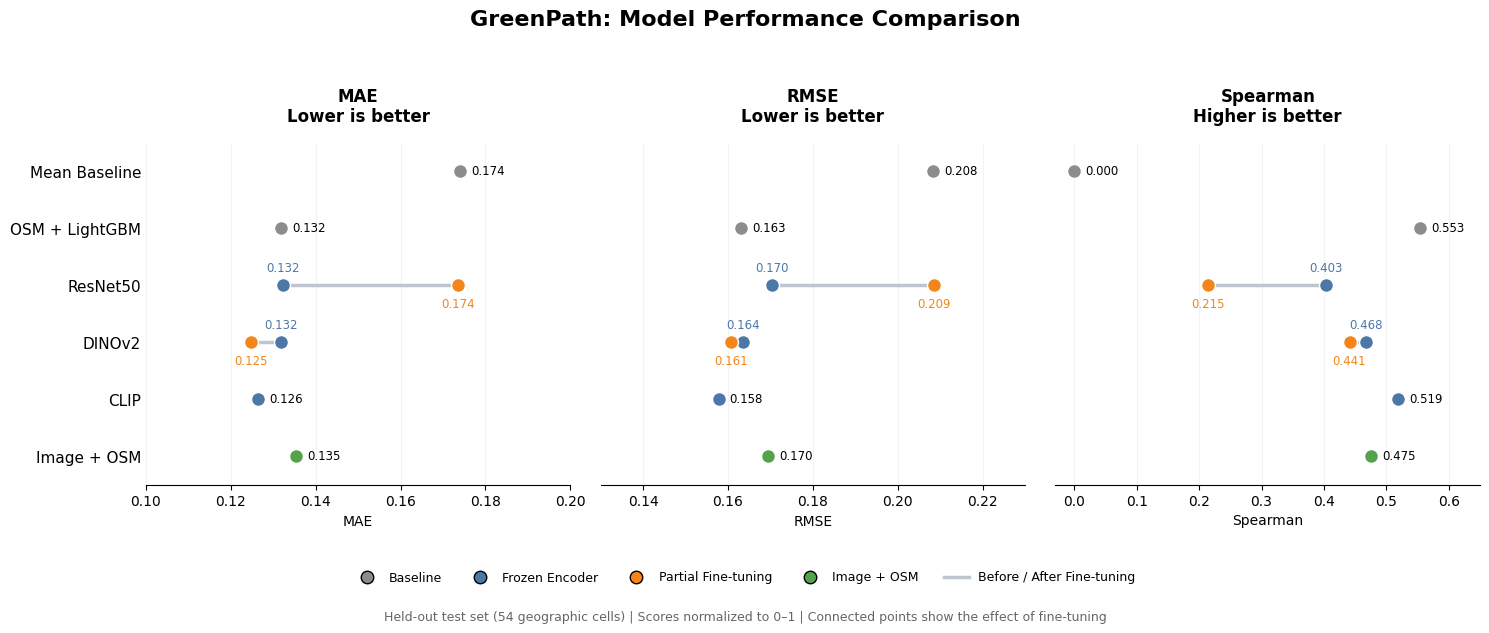

Saved: /content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results/finetuning-20261018T145711Z/model_comparison_final.png


In [5]:
# ============================================================
# GreenPath: Model Performance Comparison
# Dumbbell + Dot Plot (Aligned)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

# ------------------------------------------------------------
# 1. Load results
# ------------------------------------------------------------

RESULTS_ROOT = Path(
    "/content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results"
)

runs = sorted(
    RESULTS_ROOT.glob("finetuning-*"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

assert runs, "No fine-tuning results found."

result_file = runs[0] / "test_model_comparison_with_finetuning.csv"
df = pd.read_csv(result_file).set_index("Model")

print("Loaded:", result_file)

# ------------------------------------------------------------
# 2. Model groups and display order
# ------------------------------------------------------------

groups = [
    ("Mean Baseline", "B0: Mean Baseline", None),
    ("OSM + LightGBM", "B1: OSM + LightGBM", None),
    ("ResNet50", "Frozen ResNet50 + Ridge", "M2a: ResNet50 Partial FT"),
    ("DINOv2", "Frozen DINOv2 + Ridge", "M2b: DINOv2 Partial FT"),
    ("CLIP", "Frozen CLIP + Ridge", None),
    ("Image + OSM", "M3: Image + OSM", None),
]

# Colors
C_BASE = "#8C8C8C"
C_FROZEN = "#4C78A8"
C_FINETUNED = "#F58518"
C_FUSION = "#54A24B"
C_LINE = "#BFC5CC"

# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------

metrics = [
    ("MAE", "Lower is better"),
    ("RMSE", "Lower is better"),
    ("Spearman", "Higher is better"),
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5.5),
    sharey=True
)

y = np.arange(len(groups))

for ax, (metric, direction) in zip(axes, metrics):

    for i, (label, frozen_key, ft_key) in enumerate(groups):

        frozen_val = float(df.loc[frozen_key, metric])

        if ft_key is not None:

            ft_val = float(df.loc[ft_key, metric])

            # Connect frozen and fine-tuned results
            ax.plot(
                [frozen_val, ft_val],
                [i, i],
                color=C_LINE,
                linewidth=2.5,
                zorder=1
            )

            # Frozen point
            ax.scatter(
                frozen_val, i,
                s=100,
                color=C_FROZEN,
                edgecolor="white",
                linewidth=1,
                zorder=3
            )

            # Fine-tuned point
            ax.scatter(
                ft_val, i,
                s=100,
                color=C_FINETUNED,
                edgecolor="white",
                linewidth=1,
                zorder=3
            )

            # Numeric labels: alternate above and below
            ax.annotate(
                f"{frozen_val:.3f}",
                (frozen_val, i),
                xytext=(0, 10),
                textcoords="offset points",
                ha="center",
                fontsize=8.5,
                color=C_FROZEN
            )

            ax.annotate(
                f"{ft_val:.3f}",
                (ft_val, i),
                xytext=(0, -16),
                textcoords="offset points",
                ha="center",
                fontsize=8.5,
                color=C_FINETUNED
            )

        else:

            if label in ["Mean Baseline", "OSM + LightGBM"]:
                color = C_BASE
            elif label == "Image + OSM":
                color = C_FUSION
            else:
                color = C_FROZEN

            ax.scatter(
                frozen_val, i,
                s=100,
                color=color,
                edgecolor="white",
                linewidth=1,
                zorder=3
            )

            ax.annotate(
                f"{frozen_val:.3f}",
                (frozen_val, i),
                xytext=(8, 0),
                textcoords="offset points",
                va="center",
                fontsize=8.5
            )

    ax.set_title(
        f"{metric}\n{direction}",
        fontsize=12,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(metric, fontsize=10)

    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.tick_params(axis="y", length=0)

    # Metric-specific axis limits
    if metric == "MAE":
        ax.set_xlim(0.10, 0.20)
    elif metric == "RMSE":
        ax.set_xlim(0.13, 0.23)
    else:
        ax.set_xlim(-0.03, 0.65)

# Shared model labels
axes[0].set_yticks(y)
axes[0].set_yticklabels(
    [g[0] for g in groups],
    fontsize=11
)

axes[0].set_ylim(len(groups) - 0.5, -0.5)

# ------------------------------------------------------------
# 4. Legend
# ------------------------------------------------------------

legend_elements = [
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=C_BASE, markersize=9,
           label="Baseline"),

    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=C_FROZEN, markersize=9,
           label="Frozen Encoder"),

    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=C_FINETUNED, markersize=9,
           label="Partial Fine-tuning"),

    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=C_FUSION, markersize=9,
           label="Image + OSM"),

    Line2D([0], [0], color=C_LINE, linewidth=2.5,
           label="Before / After Fine-tuning")
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.035),
    ncol=5,
    frameon=False,
    fontsize=9
)

# ------------------------------------------------------------
# 5. Title and save
# ------------------------------------------------------------

fig.suptitle(
    "GreenPath: Model Performance Comparison",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

fig.text(
    0.5, -0.08,
    "Held-out test set (54 geographic cells) | "
    "Scores normalized to 0–1 | "
    "Connected points show the effect of fine-tuning",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.98])

output_file = runs[0] / "model_comparison_final.png"

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_file)

Fine-tuning: /content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results/finetuning-20261018T145711Z
Baseline: /content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results/baselines-first-run-20261018T1446


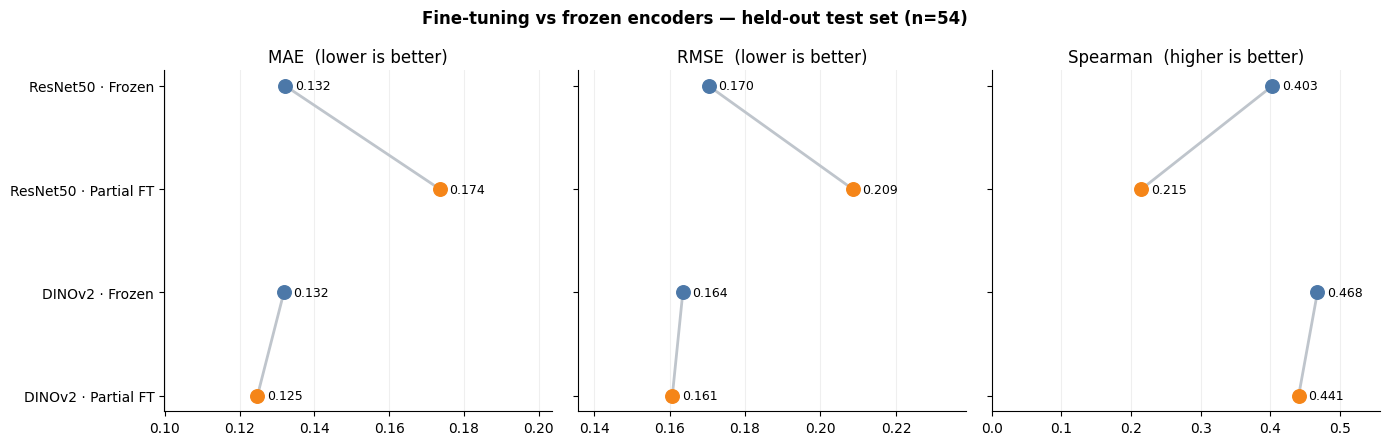

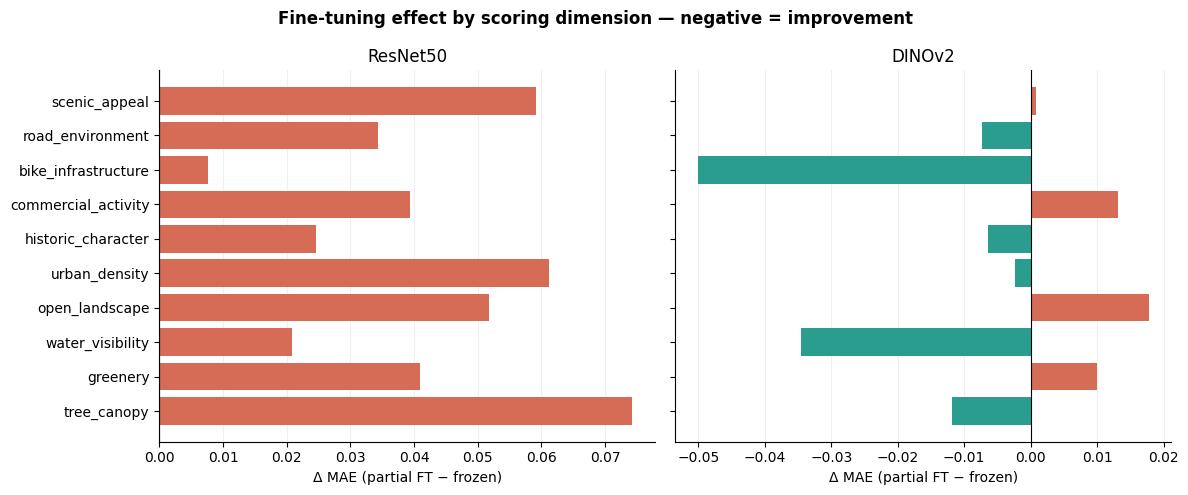

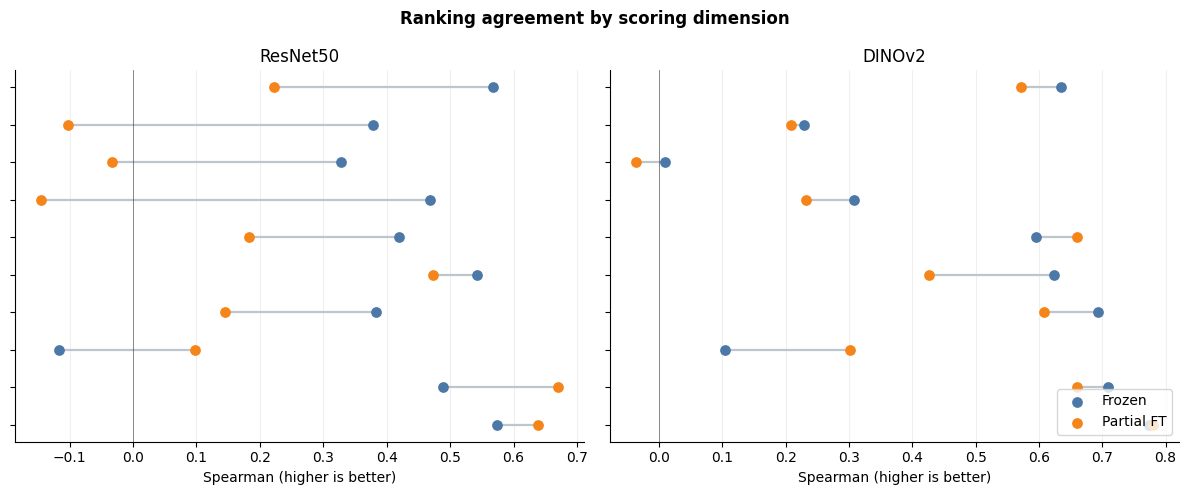

Saved plots and detailed tables to: /content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results/finetuning-20261018T145711Z/figures


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_ROOT = Path('/content/drive/MyDrive/Oct17DimensionTrainingVLM/data')
BASE_DIR = DATA_ROOT / 'results'
ft_runs = [p for p in BASE_DIR.glob('finetuning-*') if (p / 'test_per_dimension_finetuning.csv').exists() and (p / 'test_model_comparison_with_finetuning.csv').exists()]
assert ft_runs, 'No completed fine-tuning run found.'
ft_run = max(ft_runs, key=lambda p: p.stat().st_mtime)
base_runs = [p for p in BASE_DIR.iterdir() if p.is_dir() and (p / 'per_dimension_metrics.csv').exists()]
assert base_runs, 'No Notebook 07 per_dimension_metrics.csv found.'
base_run = max(base_runs, key=lambda p: p.stat().st_mtime)
print('Fine-tuning:', ft_run)
print('Baseline:', base_run)

ft = pd.read_csv(ft_run / 'test_per_dimension_finetuning.csv')
base = pd.read_csv(base_run / 'per_dimension_metrics.csv')
base = base[base['split'].eq('test') & base['model'].isin(['M1_resnet50', 'M1_dinov2_s'])].copy()
base['model'] = base['model'].map({'M1_resnet50':'ResNet50 · Frozen', 'M1_dinov2_s':'DINOv2 · Frozen'})
ft['model'] = ft['model'].map({'resnet50':'ResNet50 · Partial FT', 'dinov2_s':'DINOv2 · Partial FT'})
base = base[['dimension','model','MAE','RMSE','Spearman','n']]
ft = ft[['dimension','model','MAE','RMSE','Spearman','n']]
full = pd.concat([base,ft], ignore_index=True)
assert len(full) == 40 and full.groupby(['dimension','model']).size().eq(1).all(), 'Expected 10 dimensions x 4 models.'

# Confirm dataset alignment before combining runs.
ft_config = pd.read_json(ft_run / 'config.json', typ='series')
assert ft_config['dataset_version'] == 'v1', 'Check dataset version.'

fig_dir = ft_run / 'figures'
fig_dir.mkdir(exist_ok=True)
order = list(full[full.model.eq('ResNet50 · Frozen')]['dimension'])
models = ['ResNet50 · Frozen','ResNet50 · Partial FT','DINOv2 · Frozen','DINOv2 · Partial FT']
colors = {'ResNet50 · Frozen':'#4C78A8','ResNet50 · Partial FT':'#F58518',
          'DINOv2 · Frozen':'#4C78A8','DINOv2 · Partial FT':'#F58518'}

# Figure 1: Overall metrics (macro average over ten dimensions).
summary = full.groupby('model',sort=False)[['MAE','RMSE','Spearman']].mean().reindex(models)
fig, axes = plt.subplots(1,3,figsize=(14,4.5))
for ax, metric in zip(axes,['MAE','RMSE','Spearman']):
    ys=np.arange(len(models))
    for i, model in enumerate(models):
        ax.scatter(summary.loc[model,metric],i,s=95,color=colors[model],zorder=3)
        ax.annotate(f'{summary.loc[model,metric]:.3f}',(summary.loc[model,metric],i),xytext=(7,0),textcoords='offset points',va='center',fontsize=9)
    for a,b in [(0,1),(2,3)]:
        ax.plot(summary.iloc[[a,b]][metric], [a,b],color='#BFC5CC',lw=2,zorder=1)
    ax.set_yticks(ys,models if ax is axes[0] else ['']*len(models));ax.invert_yaxis()
    ax.set_title(f'{metric}  ({"lower" if metric != "Spearman" else "higher"} is better)')
    ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    lo=min(0,summary[metric].min()) if metric=='Spearman' else summary[metric].min()-.025
    hi=summary[metric].max()+(.09 if metric=='Spearman' else .03)
    ax.set_xlim(lo,hi)
fig.suptitle('Fine-tuning vs frozen encoders — held-out test set (n=54)',fontweight='bold')
fig.tight_layout();fig.savefig(fig_dir/'ft_overall.png',dpi=220,bbox_inches='tight');plt.show()

# Figure 2: Per-dimension paired change in MAE (FT - frozen); negative is better.
fig,axes=plt.subplots(1,2,figsize=(12,5),sharey=True)
for ax,family in zip(axes,['ResNet50','DINOv2']):
    b=full[full.model.eq(family+' · Frozen')].set_index('dimension').reindex(order)
    f=full[full.model.eq(family+' · Partial FT')].set_index('dimension').reindex(order)
    delta=f['MAE']-b['MAE']
    ax.barh(order,delta,color=np.where(delta<0,'#2A9D8F','#D66B56'))
    ax.axvline(0,color='black',lw=.8);ax.invert_yaxis();ax.set_title(family)
    ax.set_xlabel('Δ MAE (partial FT − frozen)');ax.grid(axis='x',alpha=.2)
    ax.set_axisbelow(True);ax.spines[['top','right']].set_visible(False)
fig.suptitle('Fine-tuning effect by scoring dimension — negative = improvement',fontweight='bold')
fig.tight_layout();fig.savefig(fig_dir/'ft_mae_by_dimension.png',dpi=220,bbox_inches='tight');plt.show()

# Figure 3: Spearman before and after, per dimension; undefined correlations remain missing.
fig,axes=plt.subplots(1,2,figsize=(12,5),sharey=True)
for ax,family in zip(axes,['ResNet50','DINOv2']):
    b=full[full.model.eq(family+' · Frozen')].set_index('dimension').reindex(order)
    f=full[full.model.eq(family+' · Partial FT')].set_index('dimension').reindex(order)
    yy=np.arange(len(order))
    for i,d in enumerate(order):
        x0,x1=b.loc[d,'Spearman'],f.loc[d,'Spearman']
        if np.isfinite(x0) and np.isfinite(x1):ax.plot([x0,x1],[i,i],color='#BFC5CC',lw=1.6,zorder=1)
    ax.scatter(b['Spearman'],yy,label='Frozen',color='#4C78A8',s=45,zorder=2)
    ax.scatter(f['Spearman'],yy,label='Partial FT',color='#F58518',s=45,zorder=2)
    ax.axvline(0,color='black',lw=.6,alpha=.5);ax.set_yticks(yy,order if ax is axes[0] else ['']*len(order))
    ax.invert_yaxis();ax.set_xlabel('Spearman (higher is better)');ax.set_title(family)
    ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True);ax.spines[['top','right']].set_visible(False)
axes[1].legend(loc='lower right');fig.suptitle('Ranking agreement by scoring dimension',fontweight='bold')
fig.tight_layout();fig.savefig(fig_dir/'ft_spearman_by_dimension.png',dpi=220,bbox_inches='tight');plt.show()

# Full per-dimension comparison table, with both before and after values.
wide = full.pivot(index='dimension',columns='model',values=['MAE','RMSE','Spearman']).reindex(order)
wide.to_csv(fig_dir/'ft_per_dimension_comparison.csv')
summary.to_csv(fig_dir/'ft_four_model_summary.csv')
print('Saved plots and detailed tables to:',fig_dir)

## 9. Save experiment configuration and results
Record the dataset version, model names, unfrozen layers, training hyperparameters, and test metrics for reproducibility in the AC215 report.

In [ ]:
config = {
    'run_id': RUN_ID, 'dataset_version': DATASET_VERSION, 'dry_run': DRY_RUN,
    'models': SOURCES, 'fine_tuning': {'resnet50': 'layer4 + head', 'dinov2_s': 'last 2 blocks + final norm + head'},
    'epochs_max': EPOCHS, 'patience': PATIENCE, 'batch_size': BATCH_SIZE,
    'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'weight_decay': WEIGHT_DECAY,
    'loss': 'masked SmoothL1 (Huber)', 'selection_metric': 'validation MAE',
    'best_ft_by_val': BEST_FT, 'seed': SEED, 'device': str(DEVICE),
    'dims': DIMS, 'n_train': len(train_df), 'n_val': len(val_df), 'n_test': len(test_df),
    'baseline_csv': str(BASELINE_CSV), 'label_validation': 'not performed',
    'created_at': datetime.datetime.now(datetime.timezone.utc).isoformat(),
}
(OUT_DIR / 'config.json').write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding='utf-8')
print('Finished:', OUT_DIR)
print('Files:')
for p in sorted(OUT_DIR.iterdir()): print(' ', p.name)

Finished: /content/drive/MyDrive/Oct17DimensionTrainingVLM/data/results/finetuning-20261018T145711Z
Files:
  config.json
  dinov2_s_partial_best.pt
  dinov2_s_test_predictions.csv
  dinov2_s_val_predictions.csv
  resnet50_partial_best.pt
  resnet50_test_predictions.csv
  resnet50_val_predictions.csv
  test_model_comparison_with_finetuning.csv
  test_per_dimension_finetuning.csv
  training_history.csv
  validation_per_dimension.csv


## Next steps

- If `DRY_RUN=True`, change it to `False` and rerun training from the configuration cell to obtain a full experiment in a new run directory without overwriting previous outputs.
- The training set is very small. **Do not repeatedly tune hyperparameters against the test set**; collect more labels first, then select models using train/validation data.
- Notebook 09 will compare Gemini and GPT on the same street-view images and ten-dimensional prompt; human scoring is not included at this stage.